# UCS420 – Cognitive Computing · Assignment 7 (NLP-I)

**How to use this notebook:** open `UCS420_LA9_Starter.ipynb` in Colab, enter your roll number, and run its cells (they define `generate_dataset()`, `process_ticket()` and `TEST_LINES` and print your fingerprint). Then add the cells below *after* the starter cells (File → Upload notebook, or copy-paste them). **Do not edit** `generate_dataset()` or `process_ticket()`.

## 0. Setup

In [2]:
import re, string, math, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

from nltk import word_tokenize, pos_tag, bigrams
from nltk.tokenize import RegexpTokenizer
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

lemmatizer = WordNetLemmatizer()
pd.set_option("display.max_rows", 200, "display.max_columns", 50, "display.width", 200)

[nltk_data] Error loading punkt: Security Violation [pathsec.urlopen]:
[nltk_data]     refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.
[nltk_data] Error loading punkt_tab: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be S

### Starter cells go above this line
(`generate_dataset`, `process_ticket`, `TEST_LINES`, roll number → fingerprint.)

The next cell loads the dataset and adapts to whatever `process_ticket()` returns (dict or tuple). If your starter uses different key names, only the `FIELD_KEYS` dictionary needs a tweak.

In [3]:
# ---- load dataset (all answers use this dataset) ----
try:
    generate_dataset
except NameError:          # ---- fallback ONLY if the starter cells were not run (use the starter's own functions when possible) ----
    print("WARNING: starter not found - using the embedded copy of the dataset and a stand-in process_ticket().")
    _TICKETS = [
        "Laptop is showing an error after the latest update. Please help.",
        "The email keeps asking for login. This is urgent.",
        "Call me on +91 98765 43210 or 0175-239-3201.",
        "The lms crashes while opening. Can you check this?",
        "I keep getting logged out of the laptop when I use mobile hotspot. This is urgent.",
        "The Wi-Fi works, but the VPN doesn't.",
        "Error code 0x80070005 appears.",
        "I tried restarting the projector before the assignment deadline. Can you check this?",
        "Dr. Rao's lab PC (No. 14) is down.",
        "Projector keeps asking for login before the assignment deadline. Is there another solution?",
        "The laptop crashes while opening. I have tried several times!",
        "The server is not working. The same problem occurs again.",
    ]
    def generate_dataset(): return _TICKETS
    from nltk.tokenize import sent_tokenize
    from nltk.corpus import stopwords
    _SW = set(stopwords.words("english"))
    def process_ticket(text):
        sents = sent_tokenize(text)
        toks = word_tokenize(text)
        punct = [t for t in toks if all(c in string.punctuation for c in t)]
        stop = [t for t in toks if t.lower() in _SW]
        final = [t.lower() for t in toks if t not in punct and t.lower() not in _SW]
        return {"sentences": sents, "tokens": toks, "punct": punct, "stopwords": stop, "final_tokens": final}
    TEST_LINES = ["It isn't working over Wi-Fi: 95.5% uptime on firmware 2.0.1.",
                  "Mail it-help@college.edu or visit https://support.example.com/kb/42 or call +91 98765 43210."]
_raw = generate_dataset()
if isinstance(_raw, tuple):                       # e.g. (tickets, fingerprint)
    _raw = next(x for x in _raw if isinstance(x, (list, tuple)))

def _as_text(t):
    if isinstance(t, str):
        return t
    if isinstance(t, dict):
        for k in ("text", "ticket", "body", "raw", "message", "description"):
            if k in t:
                return t[k]
        return " ".join(str(v) for v in t.values() if isinstance(v, str))
    return str(t)

raw_tickets = [_as_text(t) for t in _raw]
print(f"{len(raw_tickets)} tickets loaded\n")
for i, t in enumerate(raw_tickets, 1):
    print(f"[T{i:02d}] {t}")

# ---- run process_ticket() on every ticket ----
processed = [process_ticket(t) for t in raw_tickets]
print("\nprocess_ticket() returns:", type(processed[0]).__name__)
if isinstance(processed[0], dict):
    print({k: (type(v).__name__, (len(v) if hasattr(v, "__len__") else v)) for k, v in processed[0].items()})

# ---- map the starter's output to the five lists we need ----
FIELD_KEYS = {                 # (must contain one of these, must NOT contain any of these)
    "sentences": (["sent"],                        []),
    "tokens":    (["token"],                       ["final", "punct", "stop", "unique", "filter", "clean"]),
    "punct":     (["punct"],                       []),
    "stop":      (["stop"],                        []),
    "final":     (["final", "clean", "filter"],    []),
}
POSITIONAL = ["sentences", "tokens", "punct", "stop", "final"]   # used only if a tuple/list is returned

def get_field(p, name):
    if isinstance(p, dict):
        inc, exc = FIELD_KEYS[name]
        exact = [k for k in p if k.lower() == name or k.lower() == name + "s"]
        if exact:
            return p[exact[0]]
        for k in p:
            kl = k.lower()
            if any(s in kl for s in inc) and not any(s in kl for s in exc):
                return p[k]
        raise KeyError(f"cannot find '{name}' in keys {list(p)} – edit FIELD_KEYS")
    return p[POSITIONAL.index(name)]

def n_of(v):  return len(v) if hasattr(v, "__len__") and not isinstance(v, str) else int(v)

P = [{f: get_field(p, f) for f in POSITIONAL} for p in processed]

12 tickets loaded

[T01] Laptop is showing an error after the latest update. Please help.
[T02] The email keeps asking for login. This is urgent.
[T03] Call me on +91 98765 43210 or 0175-239-3201.
[T04] The lms crashes while opening. Can you check this?
[T05] I keep getting logged out of the laptop when I use mobile hotspot. This is urgent.
[T06] The Wi-Fi works, but the VPN doesn't.
[T07] Error code 0x80070005 appears.
[T08] I tried restarting the projector before the assignment deadline. Can you check this?
[T09] Dr. Rao's lab PC (No. 14) is down.
[T10] Projector keeps asking for login before the assignment deadline. Is there another solution?
[T11] The laptop crashes while opening. I have tried several times!
[T12] The server is not working. The same problem occurs again.

process_ticket() returns: dict
{'sentences': ('list', 2), 'tokens': ('list', 13), 'punct': ('list', 2), 'stopwords': ('list', 4), 'final_tokens': ('list', 7)}


## 1. Preprocessing – `process_ticket()` on every ticket

In [4]:
rows = []
for i, d in enumerate(P, 1):
    toks = d["tokens"]
    rows.append({
        "ticket": f"T{i:02d}",
        "sentences":        n_of(d["sentences"]),
        "tokens":           n_of(toks),
        "punctuation":      n_of(d["punct"]),
        "stopwords":        n_of(d["stop"]),
        "unique_tokens":    len(set(toks)) if not isinstance(toks, int) else None,
        "final_tokens":     n_of(d["final"]),
    })
df1 = pd.DataFrame(rows).set_index("ticket")
total = df1.sum(numeric_only=True)
total.name = "TOTAL"
df1 = pd.concat([df1, total.to_frame().T])
df1 = df1.astype(int)
display(df1)

all_tok = [t for d in P for t in d["tokens"]]
print(f"Note: the TOTAL of 'unique_tokens' is the sum of per-ticket values; "
      f"unique tokens across the whole dataset = {len(set(all_tok))}.")

,sentences,tokens,punctuation,stopwords,unique_tokens,final_tokens
T01,2,13,2,4,12,7
T02,2,11,2,4,10,5
T03,1,9,1,3,9,5
T04,2,11,2,5,11,4
T05,2,18,2,8,16,8
T06,1,10,2,4,10,4
T07,1,5,1,0,5,4
T08,2,15,2,7,14,6
T09,2,13,4,3,12,6
T10,2,15,2,5,15,8


Note: the TOTAL of 'unique_tokens' is the sum of per-ticket values; unique tokens across the whole dataset = 91.


In [5]:
SEL = 0        # <- index of the selected ticket (0 = T01); change if you like
d = P[SEL]
print(f"Selected ticket T{SEL+1:02d}:\n{raw_tickets[SEL]}\n")
print("Tokens           :", list(d["tokens"]))
print("Punctuation      :", list(d["punct"]))
print("Stopwords        :", list(d["stop"]))
print("Final tokens     :", list(d["final"]))

Selected ticket T01:
Laptop is showing an error after the latest update. Please help.

Tokens           : ['Laptop', 'is', 'showing', 'an', 'error', 'after', 'the', 'latest', 'update', '.', 'Please', 'help', '.']
Punctuation      : ['.', '.']
Stopwords        : ['is', 'an', 'after', 'the']
Final tokens     : ['laptop', 'showing', 'error', 'latest', 'update', 'please', 'help']


## 2. Regex extraction and replacement (`re`)

In [6]:
# ---- patterns ----
PAT = {
    # words longer than 5 letters (>= 6 letters)
    "long_words":    r"\b[A-Za-z]{6,}\b",
    # integers / decimals / versions as ONE match: 42, 95.5, 2.0.1 (also v2.0.1 -> 2.0.1)
    "numbers":       r"0[xX][0-9A-Fa-f]+|(?<![\d.])\d+(?:\.\d+)*(?!\d)",
    # Capitalized word: upper-case first letter followed by lower-case letters
    "capitalized":   r"\b[A-Z][a-z]+(?:'[a-z]+)?\b",
    # words that start with a vowel
    "vowel_words":   r"\b[AEIOUaeiou][A-Za-z]*(?:'[a-z]+)?\b",
}
EMAIL = r"[A-Za-z0-9._%+-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+"
URL   = r"(?<![@\w.])(?:https?://|ftp://|www\.)[^\s<>\"']*[^\s<>\"'.,;:!?)\]]"
PHONE = (r"(?<![\w.-])(?:\+\d{1,3}[\s-]?)?(?:\(\d{3}\)\s?|\d{3,5}[\s-])\d{3}[\s-]\d{4}(?![\w-])"   # +1 (555) 123-4567 / 555-123-4567
         r"|(?<![\w.-])\+\d{1,3}[\s-]?\d{5}[\s-]?\d{5}(?!\d)"                                     # +91 98765 43210
         r"|(?<![\w.-])\d{5}[\s-]\d{5}(?!\d)"                                                    # 98765 43210
         r"|(?<![\w.-])\d{10}(?!\d)")                                                              # 9876543210

def mask(text):
    """URL first (a URL may contain '@'), then e-mail, then phone."""
    text = re.sub(URL,   "<URL>",   text)
    text = re.sub(EMAIL, "<EMAIL>", text)
    text = re.sub(PHONE, "<PHONE>", text)
    return text

try:
    LINES = TEST_LINES if not isinstance(TEST_LINES, str) else TEST_LINES.splitlines()
except NameError:
    LINES = []
print(len(LINES), "TEST_LINES")
for l in LINES: print("  ", l)

2 TEST_LINES
   It isn't working over Wi-Fi: 95.5% uptime on firmware 2.0.1.
   Mail it-help@college.edu or visit https://support.example.com/kb/42 or call +91 98765 43210.


In [7]:
# ---- findall on every raw ticket ----
corpus_raw = "\n".join(raw_tickets)
summary = []
for name, pat in PAT.items():
    m = re.findall(pat, corpus_raw)
    summary.append({"pattern": name, "regex": pat, "matches": len(m), "unique": len(set(m)),
                    "sample": sorted(set(m))[:12]})
display(pd.DataFrame(summary).set_index("pattern"))

print("\nPer-ticket extraction (first 3 tickets):")
for i, t in enumerate(raw_tickets[:3], 1):
    print(f"\nT{i:02d}: {t}")
    for name, pat in PAT.items():
        print(f"   {name:12s}", re.findall(pat, t))

,regex,matches,unique,sample
pattern,,,,
long_words,"\b[A-Za-z]{6,}\b",36,28,"[Laptop, Please, Projector, another, appears, ..."
numbers,0[xX][0-9A-Fa-f]+|(?<![\d.])\d+(?:\.\d+)*(?!\d),8,8,"[0175, 0x80070005, 14, 239, 3201, 43210, 91, 9..."
capitalized,\b[A-Z][a-z]+(?:'[a-z]+)?\b,21,14,"[Call, Can, Dr, Error, Fi, Is, Laptop, No, Ple..."
vowel_words,\b[AEIOUaeiou][A-Za-z]*(?:'[a-z]+)?\b,33,22,"[Error, I, Is, after, again, an, another, appe..."



Per-ticket extraction (first 3 tickets):

T01: Laptop is showing an error after the latest update. Please help.
   long_words   ['Laptop', 'showing', 'latest', 'update', 'Please']
   numbers      []
   capitalized  ['Laptop', 'Please']
   vowel_words  ['is', 'an', 'error', 'after', 'update']

T02: The email keeps asking for login. This is urgent.
   long_words   ['asking', 'urgent']
   numbers      []
   capitalized  ['The', 'This']
   vowel_words  ['email', 'asking', 'is', 'urgent']

T03: Call me on +91 98765 43210 or 0175-239-3201.
   long_words   []
   numbers      ['91', '98765', '43210', '0175', '239', '3201']
   capitalized  ['Call']
   vowel_words  ['on', 'or']


In [8]:
# ---- re.sub on raw tickets ----
changed = 0
for i, t in enumerate(raw_tickets, 1):
    m = mask(t)
    if m != t:
        changed += 1
        print(f"T{i:02d} BEFORE: {t}\n    AFTER : {m}\n")
print(f"{changed}/{len(raw_tickets)} tickets contained an e-mail, URL or phone number.")

T03 BEFORE: Call me on +91 98765 43210 or 0175-239-3201.
    AFTER : Call me on <PHONE> or <PHONE>.

1/12 tickets contained an e-mail, URL or phone number.


In [9]:
# ---- check on TEST_LINES (+ a few extra edge cases of my own) ----
EXTRA = [
    "Contact john.doe+it@mail.example.co.in or call +1 (555) 123-4567 today.",
    "Docs at https://support.example.com/kb/42?id=7, then www.example.org/help.",
    "Upgrade from 1.9 to 2.0.1 gave 95.5% uptime; also v3.4.12 and 10 users.",
    "Alice reported an Error on Windows; Outlook isn't opening. Call 555-987-6543 or 98765 43210.",
]
for l in list(LINES) + EXTRA:
    print("LINE   :", l)
    for name, pat in PAT.items():
        print(f"  {name:12s}", re.findall(pat, l))
    print("  masked      :", mask(l), "\n")

LINE   : It isn't working over Wi-Fi: 95.5% uptime on firmware 2.0.1.
  long_words   ['working', 'uptime', 'firmware']
  numbers      ['95.5', '2.0.1']
  capitalized  ['It', 'Wi', 'Fi']
  vowel_words  ['It', "isn't", 'over', 'uptime', 'on']
  masked      : It isn't working over Wi-Fi: 95.5% uptime on firmware 2.0.1. 

LINE   : Mail it-help@college.edu or visit https://support.example.com/kb/42 or call +91 98765 43210.
  long_words   ['college', 'support', 'example']
  numbers      ['42', '91', '98765', '43210']
  capitalized  ['Mail']
  vowel_words  ['it', 'edu', 'or', 'example', 'or']
  masked      : Mail <EMAIL> or visit <URL> or call <PHONE>. 

LINE   : Contact john.doe+it@mail.example.co.in or call +1 (555) 123-4567 today.
  long_words   ['Contact', 'example']
  numbers      ['1', '555', '123', '4567']
  capitalized  ['Contact']
  vowel_words  ['it', 'example', 'in', 'or']
  masked      : Contact <EMAIL> or call <PHONE> today. 

LINE   : Docs at https://support.example.com/kb/42?id

## 3. Custom tokenization – `my_tokenize()` with one `RegexpTokenizer`

In [10]:
TOKEN_PATTERN = r"""(?x)
    [A-Za-z0-9._%+-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+                      # e-mail
  | (?:https?://|ftp://|www\.)[^\s<>"']*[^\s<>"'.,;:!?)\]]                    # URL
  | (?:\+\d{1,3}[\s-]?)?(?:\(\d{3}\)\s?|\d{3,5}[\s-])\d{3}[\s-]\d{4}            # phone  +1 (555) 123-4567 / 555-123-4567
  | \+\d{1,3}[\s-]?\d{5}[\s-]?\d{5}                                           # phone  +91 98765 43210
  | \d{5}[\s-]\d{5}(?!\d)                                                    # phone  98765 43210
  | [vV]?\d+(?:\.\d+)+(?![A-Za-z\d])                                          # decimals / versions: 95.5, 2.0.1, v3.4.12
  | \w+(?:[-']\w+)*                                                           # words: isn't, Wi-Fi, state-of-the-art, 5GHz, 42
  | [^\w\s]                                                                   # any other single punctuation mark
"""
_tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return _tokenizer.tokenize(text)

demo = ["It isn't working over Wi-Fi, a state-of-the-art router: 95.5% uptime on firmware 2.0.1.",
        "Mail it-help@college.edu or visit https://support.example.com/kb/42 or call +1 (555) 123-4567 / 555-987-6543."]
for l in demo + list(LINES):
    print(l); print("  ->", my_tokenize(l), "\n")

It isn't working over Wi-Fi, a state-of-the-art router: 95.5% uptime on firmware 2.0.1.
  -> ['It', "isn't", 'working', 'over', 'Wi-Fi', ',', 'a', 'state-of-the-art', 'router', ':', '95.5', '%', 'uptime', 'on', 'firmware', '2.0.1', '.'] 

Mail it-help@college.edu or visit https://support.example.com/kb/42 or call +1 (555) 123-4567 / 555-987-6543.
  -> ['Mail', 'it-help@college.edu', 'or', 'visit', 'https://support.example.com/kb/42', 'or', 'call', '+1 (555) 123-4567', '/', '555-987-6543', '.'] 

It isn't working over Wi-Fi: 95.5% uptime on firmware 2.0.1.
  -> ['It', "isn't", 'working', 'over', 'Wi-Fi', ':', '95.5', '%', 'uptime', 'on', 'firmware', '2.0.1', '.'] 

Mail it-help@college.edu or visit https://support.example.com/kb/42 or call +91 98765 43210.
  -> ['Mail', 'it-help@college.edu', 'or', 'visit', 'https://support.example.com/kb/42', 'or', 'call', '+91 98765 43210', '.'] 



In [11]:
print("my_tokenize() on the tickets (first 3):\n")
for i, t in enumerate(raw_tickets[:3], 1):
    print(f"T{i:02d}", my_tokenize(t), "\n")

my_tokenize() on the tickets (first 3):

T01 ['Laptop', 'is', 'showing', 'an', 'error', 'after', 'the', 'latest', 'update', '.', 'Please', 'help', '.'] 

T02 ['The', 'email', 'keeps', 'asking', 'for', 'login', '.', 'This', 'is', 'urgent', '.'] 

T03 ['Call', 'me', 'on', '+91 98765 43210', 'or', '0175-239-3201', '.'] 



In [12]:
# ---- compare with word_tokenize() ----
texts = list(LINES) + demo + raw_tickets
diff_rows = []
for t in texts:
    a, b = my_tokenize(t), word_tokenize(t)
    if a != b:
        ca, cb = Counter(a), Counter(b)
        diff_rows.append({"text": t[:70] + ("…" if len(t) > 70 else ""),
                          "only_my_tokenize": sorted((ca - cb).elements()),
                          "only_word_tokenize": sorted((cb - ca).elements())})
dfd = pd.DataFrame(diff_rows)
print(f"{len(dfd)} of {len(texts)} texts tokenize differently")
display(dfd.head(25))

# pick one concrete example for each kind of difference
def first_diff(pred):
    for t in texts:
        a, b = my_tokenize(t), word_tokenize(t)
        x = set(a) ^ set(b)
        if any(pred(w) for w in x):
            return t, a, b
kinds = {
    "e-mail address":  lambda w: "@" in w,
    "URL":             lambda w: w.startswith(("http", "www", "//")) or "://" in w,
    "contraction":     lambda w: "'" in w or w.lower() in ("n't", "'s", "'re", "'ll"),
    "phone number":    lambda w: bool(re.fullmatch(r"[\d\s()+-]{7,}", w)) or w in ("(", ")"),
    "quotes/ellipsis": lambda w: w in ("``", "''", "...", "…"),
}
print()
for k, f in kinds.items():
    r = first_diff(f)
    if r:
        t, a, b = r
        print(f"--- {k} ---\ntext          : {t}\nmy_tokenize   : {a}\nword_tokenize : {b}\n")

7 of 16 texts tokenize differently


,text,only_my_tokenize,only_word_tokenize
0,It isn't working over Wi-Fi: 95.5% uptime on f...,[isn't],"[is, n't]"
1,Mail it-help@college.edu or visit https://supp...,"[+91 98765 43210, https://support.example.com/...","[+91, //support.example.com/kb/42, 43210, 9876..."
2,"It isn't working over Wi-Fi, a state-of-the-ar...",[isn't],"[is, n't]"
3,Mail it-help@college.edu or visit https://supp...,"[+1 (555) 123-4567, https://support.example.co...","[(, ), +1, //support.example.com/kb/42, 123-45..."
4,Call me on +91 98765 43210 or 0175-239-3201.,[+91 98765 43210],"[+91, 43210, 98765]"
5,"The Wi-Fi works, but the VPN doesn't.",[doesn't],"[does, n't]"
6,Dr. Rao's lab PC (No. 14) is down.,"[., Dr, Rao's]","['s, Dr., Rao]"



--- e-mail address ---
text          : Mail it-help@college.edu or visit https://support.example.com/kb/42 or call +91 98765 43210.
my_tokenize   : ['Mail', 'it-help@college.edu', 'or', 'visit', 'https://support.example.com/kb/42', 'or', 'call', '+91 98765 43210', '.']
word_tokenize : ['Mail', 'it-help', '@', 'college.edu', 'or', 'visit', 'https', ':', '//support.example.com/kb/42', 'or', 'call', '+91', '98765', '43210', '.']

--- URL ---
text          : Mail it-help@college.edu or visit https://support.example.com/kb/42 or call +91 98765 43210.
my_tokenize   : ['Mail', 'it-help@college.edu', 'or', 'visit', 'https://support.example.com/kb/42', 'or', 'call', '+91 98765 43210', '.']
word_tokenize : ['Mail', 'it-help', '@', 'college.edu', 'or', 'visit', 'https', ':', '//support.example.com/kb/42', 'or', 'call', '+91', '98765', '43210', '.']

--- contraction ---
text          : It isn't working over Wi-Fi: 95.5% uptime on firmware 2.0.1.
my_tokenize   : ['It', "isn't", 'working', 'over', 

### Differences between `my_tokenize()` and `word_tokenize()` and why

`word_tokenize()` = Punkt sentence splitting + the Penn-Treebank word tokenizer, which is rule-based and designed for ordinary prose. `my_tokenize()` is a single regex whose alternatives are ordered from most-specific (e-mail, URL, phone, version) to least-specific (word, punctuation). Typical differences (confirm each against the diff table / examples printed above for your dataset):

1. **Contractions** – `word_tokenize("isn't")` → `is`, `n't` (Treebank splits the clitic so that "not" can be recognised); `my_tokenize` keeps `isn't` as one token because the word alternative allows an internal apostrophe.
2. **E-mail addresses** – Treebank splits at `@` (`user`, `@`, `host.com`), losing the address as an entity; `my_tokenize` matches the whole address first.
3. **URLs** – Treebank breaks `https://site.com/kb` at the colon (`https`, `:`, `//site.com/kb`); `my_tokenize` keeps the URL whole.
4. **Phone numbers** – with parentheses/spaces (`(555) 123-4567`) Treebank produces `(`, `555`, `)`, `123-4567`; `my_tokenize` keeps one token. (Plain `555-123-4567` is kept whole by both.)
5. **Quotes** – Treebank converts `"` to ``` `` ``` / `''`; `my_tokenize` emits the literal `"` character.

Both keep decimals (`95.5`), versions (`2.0.1`) and hyphenated words (`Wi-Fi`, `state-of-the-art`) intact, but only because Treebank happens to leave internal `.` and `-` alone; `my_tokenize` does it by design.

## 4. Stemming and lemmatization on the unique final tokens

In [13]:
uniq_final = sorted({w for d in P for w in d["final"]})
print(len(uniq_final), "unique final tokens")

# --- choose a suffix for the Regexp stemmer from the dataset itself ---
CANDIDATES = ["ing", "ed", "ly", "tion", "er", "es", "s"]
cand = {s: [w for w in uniq_final if w.endswith(s) and len(w) >= len(s) + 3] for s in CANDIDATES}
for s, ws in cand.items():
    print(f"suffix -{s:5s}: {len(ws):3d} words  {ws[:8]}")
SUFFIX = "ing"       # chosen: showing, asking, opening, getting, restarting, working all end in -ing
assert len(cand[SUFFIX]) >= 2
EX = cand[SUFFIX][:4]
print(f"\nChosen suffix: '{SUFFIX}'   (dataset words: {EX})")

53 unique final tokens
suffix -ing  :   6 words  ['asking', 'getting', 'opening', 'restarting', 'showing', 'working']
suffix -ed   :   2 words  ['logged', 'tried']
suffix -ly   :   0 words  []
suffix -tion :   1 words  ['solution']
suffix -er   :   2 words  ['another', 'server']
suffix -es   :   2 words  ['crashes', 'times']
suffix -s    :   6 words  ['appears', 'crashes', 'keeps', 'occurs', 'times', 'works']

Chosen suffix: 'ing'   (dataset words: ['asking', 'getting', 'opening', 'restarting'])


**Justification of the Regexp-stemmer suffix.** I chose **`-ing`** from this dataset: it ends several different unique final tokens (*showing* in T01, *asking* in T02/T10, *opening* in T04/T11, *getting* in T05, *restarting* in T08, *working* in T12). Stripping it reduces them to the verb base (*asking→ask*, *opening→open*, *working→work*, *showing→show*), which is exactly what a stemmer should do, while a `min=4` guard stops very short words from being destroyed. Overly generic rules such as `-s` were not used alone because they damage words like *access*, *bus*, *status*, which are common in IT-support text.

In [14]:
porter    = PorterStemmer()
lancaster = LancasterStemmer()
regexp    = RegexpStemmer(SUFFIX + "$", min=4)

# POS tags (in context, per ticket) -> WordNet POS
def wn_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

word_pos = {}
for d in P:
    fin = list(d["final"])
    for w, tg in pos_tag(fin):
        word_pos.setdefault(w, tg)          # first POS seen for each unique word

rows = []
for w in uniq_final:
    tg = word_pos.get(w, "NN")
    rows.append({"word": w, "POS": tg,
                 "Porter": porter.stem(w),
                 "Lancaster": lancaster.stem(w),
                 "Regexp(-%s)" % SUFFIX: regexp.stem(w),
                 "WordNet lemma": lemmatizer.lemmatize(w, wn_pos(tg))})
df4 = pd.DataFrame(rows)
cols = ["Porter", "Lancaster", "Regexp(-%s)" % SUFFIX, "WordNet lemma"]
differ = df4[df4[cols].nunique(axis=1) > 1].reset_index(drop=True)
print(f"{len(differ)} of {len(df4)} words get different outputs from the four methods:")
display(differ)

28 of 53 words get different outputs from the four methods:


,word,POS,Porter,Lancaster,Regexp(-ing),WordNet lemma
0,another,DT,anoth,anoth,another,another
1,appears,VBZ,appear,appear,appears,appear
2,assignment,JJ,assign,assign,assignment,assignment
3,call,NN,call,cal,call,call
4,code,NN,code,cod,code,code
5,crashes,NNS,crash,crash,crashes,crash
6,deadline,NN,deadlin,deadlin,deadline,deadline
7,error,NN,error,er,error,error
8,getting,VBG,get,get,gett,get
9,keeps,NNS,keep,keep,keeps,keep


## 5. Corpus statistics

In [15]:
S1 = [t for d in P for t in d["tokens"]]                                        # all tokens
is_punct = lambda t: all(ch in string.punctuation for ch in t)
S2 = [t for t in S1 if not is_punct(t)]                                         # no punctuation
S3 = [t for d in P for t in d["final"]]                                         # final tokens
S4 = [porter.stem(t) for t in S3]                                               # S3 + Porter

stats = pd.DataFrame({
    name: {"total tokens": len(S), "unique tokens": len(set(S)), "TTR": len(set(S)) / len(S)}
    for name, S in [("S1 all tokens", S1), ("S2 no punctuation", S2), ("S3 final tokens", S3), ("S4 S3 + Porter", S4)]
}).T
stats[["total tokens", "unique tokens"]] = stats[["total tokens", "unique tokens"]].astype(int)
stats["TTR"] = stats["TTR"].round(4)
display(stats)

,total tokens,unique tokens,TTR
S1 all tokens,144,91,0.6319
S2 no punctuation,120,85,0.7083
S3 final tokens,67,53,0.7910
S4 S3 + Porter,67,51,0.7612


In [16]:
# 1) top-10 words of S1 and S3
for name, S in [("S1", S1), ("S3", S3)]:
    print(f"Top 10 words of {name}:")
    display(pd.DataFrame(Counter(S).most_common(10), columns=["word", "frequency"]))

Top 10 words of S1:


,word,frequency
0,.,17
1,the,6
2,The,6
3,is,5
4,I,4
5,?,3
6,keeps,2
7,asking,2
8,for,2
9,login,2


Top 10 words of S3:


,word,frequency
0,laptop,3
1,error,2
2,keeps,2
3,asking,2
4,login,2
5,urgent,2
6,crashes,2
7,opening,2
8,check,2
9,tried,2


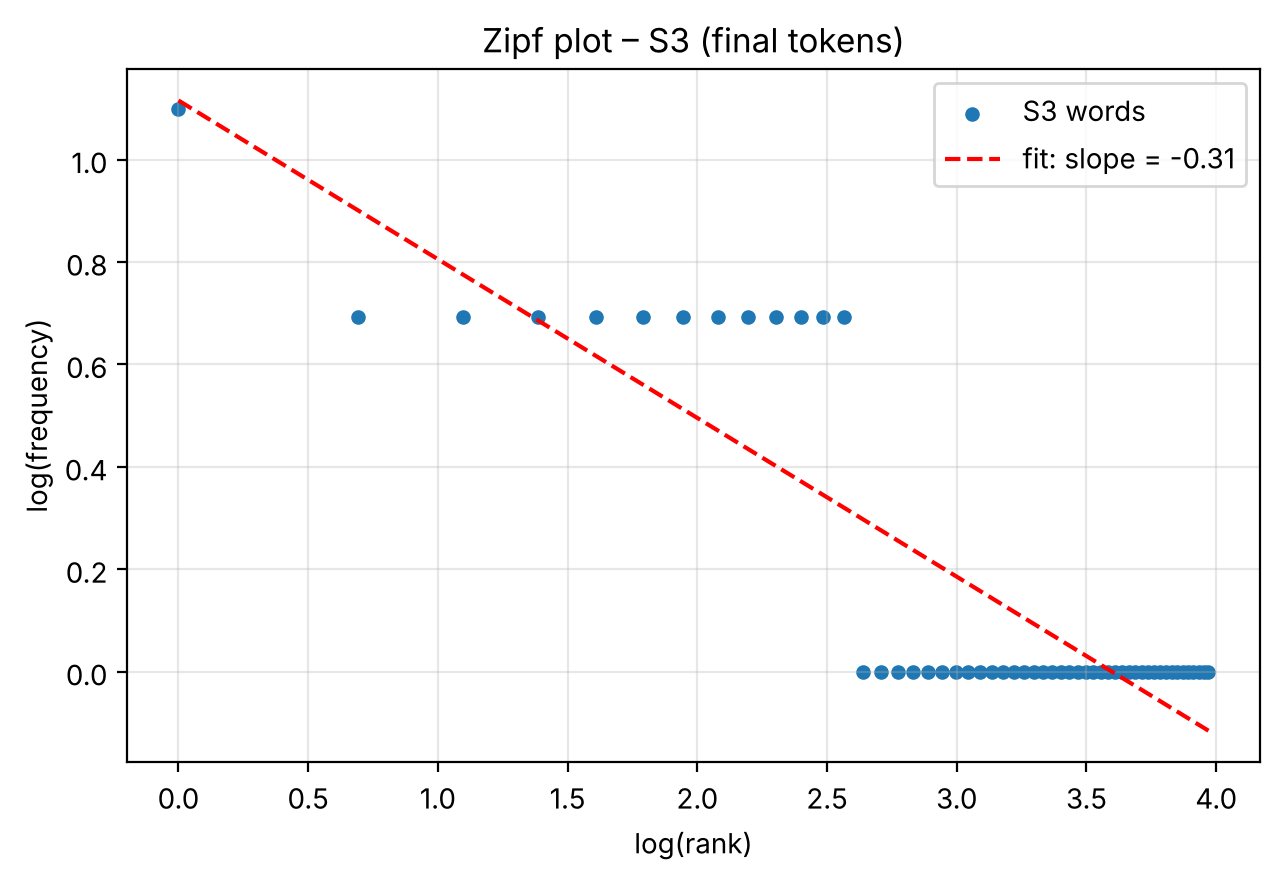

Fitted slope = -0.31 (Zipf's law predicts ≈ -1)


In [17]:
# 2) log(rank) vs log(frequency) for S3  (Zipf plot)
freq = np.array(sorted(Counter(S3).values(), reverse=True))
rank = np.arange(1, len(freq) + 1)
lx, ly = np.log(rank), np.log(freq)
slope, intercept = np.polyfit(lx, ly, 1)

plt.figure(figsize=(6.5, 4.5))
plt.scatter(lx, ly, s=18, label="S3 words")
plt.plot(lx, slope * lx + intercept, "r--", label=f"fit: slope = {slope:.2f}")
plt.xlabel("log(rank)"); plt.ylabel("log(frequency)")
plt.title("Zipf plot – S3 (final tokens)")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
print(f"Fitted slope = {slope:.2f} (Zipf's law predicts ≈ -1)")

In [18]:
# 3) top-5 bigrams (built per ticket so no bigram crosses a ticket boundary)
def top_bigrams(seqs, n=5):
    c = Counter(b for s in seqs for b in bigrams(s))
    return c.most_common(n)

for name, seqs in [("S1", [list(d["tokens"]) for d in P]), ("S3", [list(d["final"]) for d in P])]:
    print(f"Top 5 bigrams of {name}:")
    display(pd.DataFrame([(" ".join(b), c) for b, c in top_bigrams(seqs)], columns=["bigram", "count"]))

Top 5 bigrams of S1:


,bigram,count
0,keeps asking,2
1,asking for,2
2,for login,2
3,. This,2
4,This is,2


Top 5 bigrams of S3:


,bigram,count
0,keeps asking,2
1,asking login,2
2,crashes opening,2
3,assignment deadline,2
4,laptop showing,1


## 6. Interpretation

In [19]:
t = stats["TTR"]
print("TTR  S1 = %.4f | S2 = %.4f | S3 = %.4f | S4 = %.4f" % tuple(t))
print("Totals:", dict(stats["total tokens"]), "\nUnique:", dict(stats["unique tokens"]))

TTR  S1 = 0.6319 | S2 = 0.7083 | S3 = 0.7910 | S4 = 0.7612
Totals: {'S1 all tokens': np.int64(144), 'S2 no punctuation': np.int64(120), 'S3 final tokens': np.int64(67), 'S4 S3 + Porter': np.int64(67)} 
Unique: {'S1 all tokens': np.int64(91), 'S2 no punctuation': np.int64(85), 'S3 final tokens': np.int64(53), 'S4 S3 + Porter': np.int64(51)}


**(a) Why does TTR change from S1 to S4?**
TTR = unique ÷ total, so it rises whenever *repeated* tokens are removed and falls whenever distinct types are merged.
- **S1 → S2:** punctuation marks (`.`, `,`, `:`, …) are few types but many tokens, so removing them cuts the total much more than the unique count → TTR increases.
- **S2 → S3:** stopwords (*the, to, is, …*) are also very frequent, so dropping them (and whatever else `process_ticket()` removes) again shrinks the total faster than the vocabulary → TTR increases again; the remaining text is dominated by content words.
- **S3 → S4:** Porter stemming does not change the number of tokens, but it maps inflected variants (*reset/resets/resetting*) to one stem, lowering the unique count → TTR decreases relative to S3.

Hence TTR is highest for S3 and lower for S4 in this dataset (see the table above for the exact numbers); S1 is lowest because it is dominated by repeated function words and punctuation.

In [20]:
# (b) example where word_tokenize() and my_tokenize() differ
ex = None
for t_ in list(LINES) + demo + raw_tickets:
    a, b = my_tokenize(t_), word_tokenize(t_)
    if a != b:
        ca, cb = Counter(a), Counter(b)
        ex = (t_, sorted((ca - cb).elements()), sorted((cb - ca).elements()))
        break
if ex:
    print("Text                      :", ex[0])
    print("Only in my_tokenize       :", ex[1])
    print("Only in word_tokenize     :", ex[2])

Text                      : It isn't working over Wi-Fi: 95.5% uptime on firmware 2.0.1.
Only in my_tokenize       : ["isn't"]
Only in word_tokenize     : ['is', "n't"]


**(b)** Example (see the cell above, and section 3): for `"It isn't working"`, `word_tokenize` gives `['It', 'is', "n't", 'working']` while `my_tokenize` gives `['It', "isn't", 'working']`. Treebank deliberately splits the negation clitic `n't` off its host word; my regex treats the apostrophe as an *internal* character of a word (`\w+(?:[-']\w+)*`), so the contraction stays one token. The same mechanism explains the e-mail/URL differences: `word_tokenize` breaks them at `@` and `:`, whereas `my_tokenize` tries the e-mail and URL alternatives first.

In [21]:
# (c) undesirable stemming: (i) over-stemming = different words -> same stem, (ii) stem that is not a real word
from collections import defaultdict
by_stem = defaultdict(list)
for w in uniq_final: by_stem[porter.stem(w)].append(w)
over = {s: ws for s, ws in by_stem.items() if len(ws) > 1 and len({lemmatizer.lemmatize(w, wn_pos(word_pos.get(w, "NN"))) for w in ws}) > 1}
print("Different words collapsed to the same Porter stem (over-stemming):")
for s, ws in list(over.items())[:10]: print(f"   {ws} -> '{s}'")
print("\nStems that are not dictionary words:")
bad = [(w, porter.stem(w)) for w in uniq_final if not wordnet.synsets(porter.stem(w))]
print("  ", bad[:12])

Different words collapsed to the same Porter stem (over-stemming):

Stems that are not dictionary words:


   [("'s", "'s"), ('+91', '+91'), ('0175-239-3201', '0175-239-3201'), ('0x80070005', '0x80070005'), ('43210', '43210'), ('98765', '98765'), ('another', 'anoth'), ('deadline', 'deadlin'), ('login', 'login'), ('mobile', 'mobil'), ("n't", "n't"), ('rao', 'rao')]


**(c)** Porter works on character patterns, not meaning, so it can output non-words or merge/alter meaning. In this dataset: *update → updat* (T01), *solution → solut* (T10), *deadline → deadlin* (T08, T10) are not words, and *several → sever* (T11) turns a quantity word into a different word altogether (*sever* = to cut). Also *assignment → assign* loses the noun sense (a piece of coursework becomes a verb). Such stems are unreadable and can conflate unrelated terms in IT-support search or classification.

In [22]:
# (d) POS-aware lemmatization vs stemming: show words where the lemma is a real, meaningful word
#     but the stem is a truncated non-word (or where POS changes the lemma)
rows = []
for w in uniq_final:
    tg = word_pos.get(w, "NN"); pos = wn_pos(tg)
    lem, stm = lemmatizer.lemmatize(w, pos), porter.stem(w)
    rows.append({"word": w, "POS": tg, "stem(Porter)": stm, "lemma(POS-aware)": lem,
                 "lemma(no POS)": lemmatizer.lemmatize(w),
                 "stem is word?": bool(wordnet.synsets(stm)), "lemma is word?": bool(wordnet.synsets(lem))})
dd = pd.DataFrame(rows)
good = dd[(dd["lemma is word?"]) & (~dd["stem is word?"])]
pos_effect = dd[dd["lemma(POS-aware)"] != dd["lemma(no POS)"]]
print("Lemma is a valid word but the stem is not:"); display(good.head(10))
print("Words where passing the POS changes the lemma:"); display(pos_effect.head(10))

Lemma is a valid word but the stem is not:


,word,POS,stem(Porter),lemma(POS-aware),lemma(no POS),stem is word?,lemma is word?
7,another,DT,anoth,another,another,False,True
15,deadline,NN,deadlin,deadline,deadline,False,True
30,mobile,JJ,mobil,mobile,mobile,False,True
43,solution,NN,solut,solution,solution,False,True
45,tried,JJ,tri,tried,tried,False,True
46,update,JJ,updat,update,update,False,True


Words where passing the POS changes the lemma:


,word,POS,stem(Porter),lemma(POS-aware),lemma(no POS),stem is word?,lemma is word?
8,appears,VBZ,appear,appear,appears,True,True
9,asking,VBG,ask,ask,asking,True,True
19,getting,VBG,get,get,getting,True,True
26,latest,JJS,latest,late,latest,True,True
27,lms,JJ,lm,lms,lm,True,True
33,opening,VBG,open,open,opening,True,True
39,restarting,VBG,restart,restart,restarting,True,True
42,showing,VBG,show,show,showing,True,True
51,working,VBG,work,work,working,True,True


**(d)** A lemmatizer uses a dictionary plus the POS tag, so it returns real words. In T08 (*"I tried restarting the projector…"*) Porter turns *tried* into **tri**, whereas `lemmatize("tried", "v")` gives **try**; in T02/T10 *asking* → `lemmatize(…, "v")` = **ask**; in T05 *logged* (VBN) → **log**; and *update* stays **update** instead of Porter's **updat**. POS matters: without a POS tag the lemmatizer assumes a noun and would leave *tried* or *logged* unchanged, so the POS information is what recovers *try* and *log*. A stemmer ignores POS entirely, so only the lemmatizer preserves the meaning (*tried → try*).